# 04 — Clustering (R2)

**Project:** Birds' Species Classification · **Requirement:** R2 (clustering to find patterns in the data)

Clustering is **unsupervised**: the algorithm never sees the species labels. We use it to answer two questions:

1. **Image level** — do the 11,769 attribute vectors form natural groups that match species?
2. **Species level** — if we describe each species by its average attributes (its *profile*), which species group together,
   and what attributes define each group?

Methods from Tutorial 4 and the course: **K-Means** (elbow method with inertia, silhouette score) and a
**Gaussian Mixture Model** fitted with the **EM algorithm** (a generative, "soft" clustering method, chosen with BIC).
Because we *do* know the true labels, we can also measure how well clusters agree with them using the
**Adjusted Rand Index (ARI)**: 0 = no better than random, 1 = perfect agreement.

**Input:** `data/processed/cub_attributes_clean.csv`

**Contents**
1. Setup
2. Image level: K-Means, choosing *k*
3. Image level: do clusters recover species?
4. Species level: K-Means on species profiles
5. Species level: Gaussian Mixture Model (EM)
6. Interpreting the species clusters
7. Limitations and findings

## 1. Setup

In [1]:
import sys
sys.path.insert(0, "../scripts")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

import r2_utils as u

u.set_plot_style()

# On Windows, scikit-learn prints a harmless memory-leak notice for K-Means on small data; hide it
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

df = u.load_attributes(clean=True)
ATTR = u.attribute_columns(df)
X = df[ATTR].values.astype(float)
print(f"{X.shape[0]:,} images x {X.shape[1]} attributes")

11,769 images x 312 attributes


## 2. Image level: K-Means and choosing *k*

As in Tutorial 4, we run K-Means for a range of *k* and look at two curves:

* **Inertia** (sum of squared distances to the nearest centroid) always decreases with *k*; we look for an **elbow**.
* **Silhouette score** (−1 to 1): close to 1 means points sit well inside their cluster and far from others.
  Computed on a random sample of 3,000 images to keep it fast.

`n_init=10` runs K-Means 10 times from different starting centroids and keeps the best, to avoid poor local solutions.

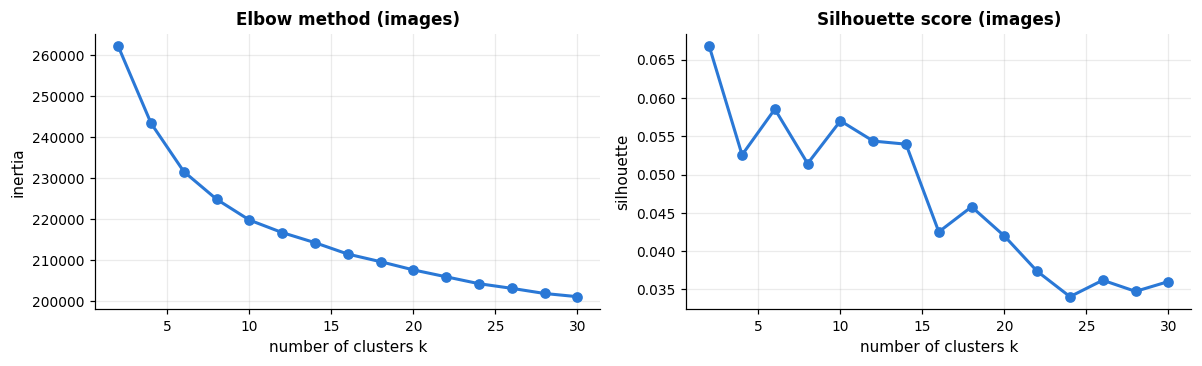

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
k,2.000,4.000,6.000,8.000,10.000,12.000,14.000,16.000,18.000,20.000,22.000,24.000,26.000,28.000,30.000
inertia,262102.000,243327.000,231519.000,224765.000,219694.000,216637.000,214171.000,211387.000,209525.000,207521.000,205838.000,204155.000,203022.000,201767.000,200984.000
silhouette,0.067,0.053,0.059,0.051,0.057,0.054,0.054,0.043,0.046,0.042,0.037,0.034,0.036,0.035,0.036


In [2]:
k_values = list(range(2, 31, 2))
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=u.RANDOM_STATE).fit(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_, sample_size=3000, random_state=u.RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(k_values, inertias, marker="o", color=u.BLUE, lw=2)
axes[0].set(title="Elbow method (images)", xlabel="number of clusters k", ylabel="inertia")
axes[1].plot(k_values, silhouettes, marker="o", color=u.BLUE, lw=2)
axes[1].set(title="Silhouette score (images)", xlabel="number of clusters k", ylabel="silhouette")
plt.tight_layout()
u.save_figure(fig, "04_image_k_selection")
plt.show()

pd.DataFrame({"k": k_values, "inertia": np.round(inertias), "silhouette": np.round(silhouettes, 3)}).T

**Finding:** the inertia curve bends smoothly with **no clear elbow**, and silhouette scores are **very low** (close to 0)
for every *k*. In other words, the images do **not** form well-separated natural groups in attribute space —
consistent with the EDA (sparse, noisy vectors; no low-dimensional structure).

## 3. Image level: do clusters recover species?

If each species formed its own tight group, K-Means with **k = 200** would recover the species.
We compare the clusters with the true species (and with the 70 name groups, e.g. "Gull", "Warbler") using ARI.

In [3]:
km200 = KMeans(n_clusters=200, n_init=3, random_state=u.RANDOM_STATE).fit(X)

agreement = pd.DataFrame({
    "ARI": [adjusted_rand_score(df["class_id"], km200.labels_),
            adjusted_rand_score(df["name_group"], km200.labels_)],
}, index=["vs. 200 species", "vs. 70 name groups"]).round(3)
agreement

,ARI
vs. 200 species,0.122
vs. 70 name groups,0.058


In [4]:
# Purity: for each cluster, what share of its images belong to its most common species?
purity = (df.assign(cluster=km200.labels_)
            .groupby("cluster")["species"]
            .agg(size="size", top_species=lambda s: s.value_counts().index[0],
                 purity=lambda s: s.value_counts(normalize=True).iloc[0]))
print(f"Median cluster purity: {purity['purity'].median():.0%} "
      f"(a perfect species clustering would be 100%)")
purity.sort_values("purity", ascending=False).head(8).round(2)

Median cluster purity: 21% (a perfect species clustering would be 100%)


,size,top_species,purity
cluster,,,
128,5,Ringed Kingfisher,1.00
161,29,White breasted Kingfisher,1.00
192,41,European Goldfinch,0.98
0,52,Red headed Woodpecker,0.96
122,40,Mallard,0.95
153,57,Pileated Woodpecker,0.95
88,37,Painted Bunting,0.95
14,35,Cardinal,0.94


**Finding:** agreement with species is **weak**: ARI = 0.12 (0 would be random, 1 perfect) and the median cluster
contains only about 21% of a single species. A few clusters are almost pure — distinctive species such as the
Kingfishers, European Goldfinch, Mallard or Painted Bunting — but most clusters mix several species.
Clustering is therefore **not** a substitute for supervised classification here, but it confirms that some species are
naturally distinctive while many overlap.

## 4. Species level: K-Means on species profiles

Individual images are noisy. Averaging the attributes over all images of a species gives a cleaner **profile**
(value = share of the species' images with that attribute). Clustering the 200 profiles shows **which species are
described similarly**, i.e. natural groupings of birds by appearance.

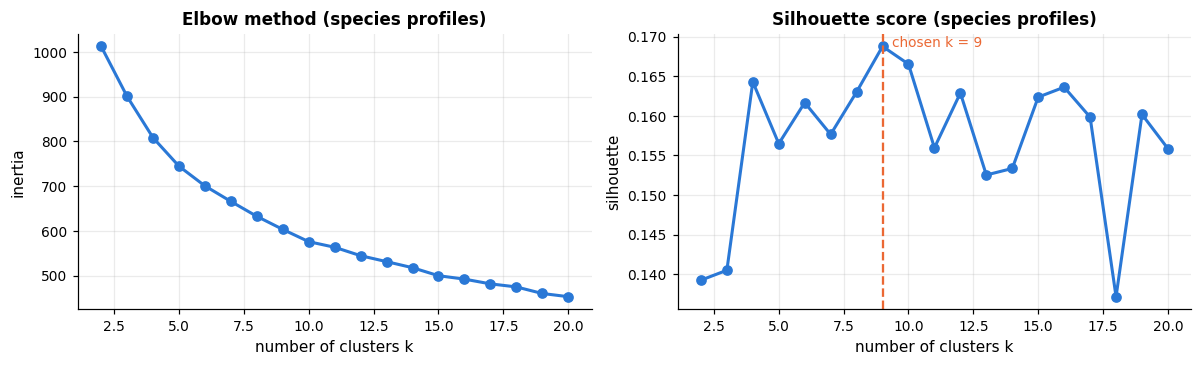

Chosen k = 9 (silhouette 0.169)


In [5]:
profiles = df.groupby("species")[ATTR].mean()
name_group = df.drop_duplicates("species").set_index("species").loc[profiles.index, "name_group"]
P = profiles.values

k_values_sp = list(range(2, 21))
sp_inertias, sp_silhouettes = [], []
for k in k_values_sp:
    km = KMeans(n_clusters=k, n_init=20, random_state=u.RANDOM_STATE).fit(P)
    sp_inertias.append(km.inertia_)
    sp_silhouettes.append(silhouette_score(P, km.labels_))

# Choose k: the best silhouette between 4 and 15 (fewer than 4 groups is too coarse to be useful,
# more than 15 is too many to interpret)
candidates = [(s, k) for k, s in zip(k_values_sp, sp_silhouettes) if 4 <= k <= 15]
best_k = max(candidates)[1]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(k_values_sp, sp_inertias, marker="o", color=u.BLUE, lw=2)
axes[0].set(title="Elbow method (species profiles)", xlabel="number of clusters k", ylabel="inertia")
axes[1].plot(k_values_sp, sp_silhouettes, marker="o", color=u.BLUE, lw=2)
axes[1].axvline(best_k, color=u.ORANGE, ls="--")
axes[1].annotate(f"chosen k = {best_k}", (best_k, max(sp_silhouettes)), xytext=(6, 0),
                 textcoords="offset points", color=u.ORANGE, fontsize=9)
axes[1].set(title="Silhouette score (species profiles)", xlabel="number of clusters k", ylabel="silhouette")
plt.tight_layout()
u.save_figure(fig, "04_species_k_selection")
plt.show()
print(f"Chosen k = {best_k} (silhouette {max(candidates)[0]:.3f})")

In [6]:
km_sp = KMeans(n_clusters=best_k, n_init=50, random_state=u.RANDOM_STATE).fit(P)
species_clusters = pd.Series(km_sp.labels_, index=profiles.index, name="kmeans")

print("Cluster sizes (number of species):", species_clusters.value_counts().sort_index().to_dict())
print(f"Agreement with the 70 name groups: ARI = {adjusted_rand_score(name_group, species_clusters):.3f}")

Cluster sizes (number of species): {0: 18, 1: 33, 2: 20, 3: 18, 4: 24, 5: 11, 6: 7, 7: 44, 8: 25}
Agreement with the 70 name groups: ARI = 0.230


## 5. Species level: Gaussian Mixture Model (EM algorithm)

A GMM assumes the data come from a mix of Gaussian distributions and fits them with the **Expectation–Maximisation**
algorithm: the E-step computes each point's probability of belonging to each component, the M-step re-estimates the
components. Unlike K-Means it gives **soft** assignments (probabilities).

With only 200 profiles and 312 dimensions a full covariance matrix cannot be estimated, so we first reduce the
profiles to 10 principal components and use diagonal covariances. The number of components is chosen with the
**Bayesian Information Criterion (BIC)** — lower is better; it rewards fit but penalises complexity.

10 components keep 72% of the variance of the profiles


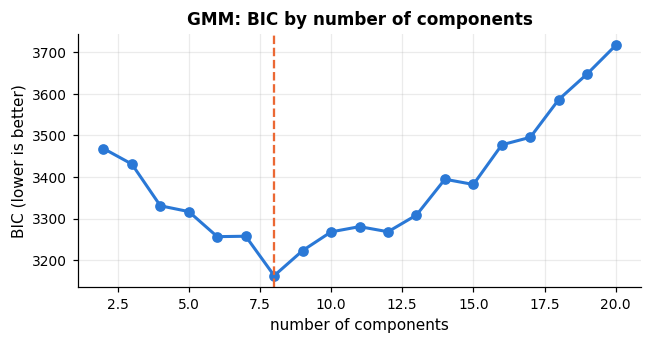

BIC chooses 8 components
Agreement GMM vs K-Means (ARI): 0.485
Agreement GMM vs name groups:   ARI = 0.176
Species assigned with < 90% probability (uncertain between components): 18


In [7]:
pca10 = PCA(n_components=10, random_state=u.RANDOM_STATE).fit(P)
P10 = pca10.transform(P)
print(f"10 components keep {pca10.explained_variance_ratio_.sum():.0%} of the variance of the profiles")

bics = []
for k in k_values_sp:
    gmm = GaussianMixture(n_components=k, covariance_type="diag", n_init=5, random_state=u.RANDOM_STATE).fit(P10)
    bics.append(gmm.bic(P10))
gmm_k = k_values_sp[int(np.argmin(bics))]

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(k_values_sp, bics, marker="o", color=u.BLUE, lw=2)
ax.axvline(gmm_k, color=u.ORANGE, ls="--")
ax.set(title="GMM: BIC by number of components", xlabel="number of components", ylabel="BIC (lower is better)")
plt.tight_layout()
u.save_figure(fig, "04_gmm_bic")
plt.show()

gmm = GaussianMixture(n_components=gmm_k, covariance_type="diag", n_init=10,
                      random_state=u.RANDOM_STATE).fit(P10)
gmm_labels = pd.Series(gmm.predict(P10), index=profiles.index, name="gmm")
confidence = gmm.predict_proba(P10).max(axis=1)

print(f"BIC chooses {gmm_k} components")
print(f"Agreement GMM vs K-Means (ARI): {adjusted_rand_score(species_clusters, gmm_labels):.3f}")
print(f"Agreement GMM vs name groups:   ARI = {adjusted_rand_score(name_group, gmm_labels):.3f}")
print(f"Species assigned with < 90% probability (uncertain between components): {(confidence < 0.9).sum()}")

## 6. Interpreting the species clusters (K-Means)

For each cluster we list the attributes that are **much more common in the cluster than overall**, plus its member species.

In [8]:
overall = profiles.mean()
rows = []
for c in sorted(species_clusters.unique()):
    members = species_clusters[species_clusters == c].index
    lift = (profiles.loc[members].mean() - overall).sort_values(ascending=False)
    groups = name_group[members].value_counts()
    rows.append({
        "cluster": c,
        "n species": len(members),
        "defining attributes": ", ".join(a.replace("has_", "") for a in lift.index[:4]),
        "most common name groups": ", ".join(f"{g} ({n})" for g, n in groups.head(4).items()),
    })
cluster_table = pd.DataFrame(rows).set_index("cluster")
with pd.option_context("display.max_colwidth", 90):
    display(cluster_table)

,n species,defining attributes,most common name groups
cluster,,,
0,18,"size::medium_(9_-_16_in), shape::duck-like, bill_length::about_the_same_as_head, bill_...","Grebe (4), Albatross (2), Merganser (2), Jaeger (2)"
1,33,"nape_color::grey, primary_color::grey, crown_color::grey, bill_shape::all-purpose","Flycatcher (6), Vireo (6), Warbler (5), Waxwing (2)"
2,20,"primary_color::blue, crown_color::blue, upperparts_color::blue, forehead_color::blue","Hummingbird (3), Swallow (3), Kingfisher (3), Jay (3)"
3,18,"nape_color::white, forehead_color::white, throat_color::white, primary_color::white","Gull (8), Tern (6), Albatross (1), Fulmar (1)"
4,24,"throat_color::black, primary_color::black, underparts_color::black, belly_color::black","Blackbird (4), Cormorant (3), Crow (2), Cowbird (2)"
5,11,"primary_color::black, wing_color::white, primary_color::white, upperparts_color::white","Woodpecker (5), Kingfisher (2), Auklet (2), Warbler (1)"
6,7,"primary_color::red, breast_color::red, underparts_color::red, belly_color::red","Tanager (2), Cardinal (1), Bunting (1), Grosbeak (1)"
7,44,"wing_color::brown, primary_color::brown, upperparts_color::brown, crown_color::brown","Sparrow (20), Wren (7), Thrasher (2), Waterthrush (2)"
8,25,"underparts_color::yellow, belly_color::yellow, breast_color::yellow, primary_color::ye...","Warbler (15), Oriole (3), Goldfinch (1), Yellowthroat (1)"


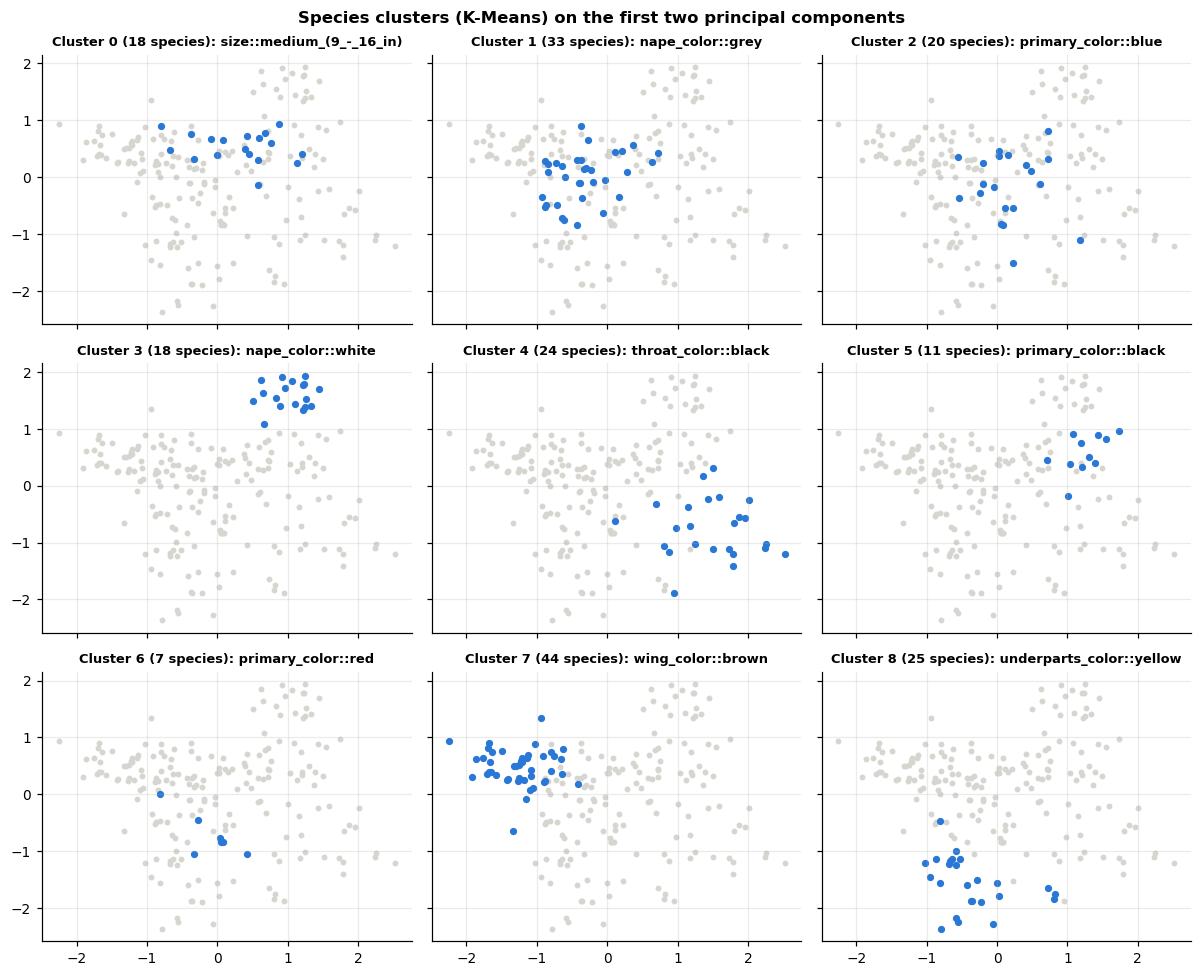

In [9]:
# Small multiples: each panel highlights one cluster on a 2-D PCA map of the 200 species
Z = PCA(n_components=2, random_state=u.RANDOM_STATE).fit_transform(P)
n_cols = 3
n_rows = int(np.ceil(best_k / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(11, 3.0 * n_rows), sharex=True, sharey=True)
for c, ax in zip(range(best_k), axes.ravel()):
    m = (species_clusters == c).values
    ax.scatter(Z[~m, 0], Z[~m, 1], s=8, color="#d6d5d0")
    ax.scatter(Z[m, 0], Z[m, 1], s=14, color=u.BLUE)
    top_attr = cluster_table.loc[c, "defining attributes"].split(", ")[0]     # e.g. 'primary_color::black'
    ax.set_title(f"Cluster {c} ({m.sum()} species): {top_attr}", fontsize=8.5)
for ax in axes.ravel()[best_k:]:
    ax.axis("off")
fig.suptitle("Species clusters (K-Means) on the first two principal components", fontweight="bold")
plt.tight_layout()
u.save_figure(fig, "04_species_clusters")
plt.show()

In [10]:
# Do look-alike species (from notebook 02) end up in the same cluster?
pairs = [("American Crow", "Fish Crow"), ("California Gull", "Herring Gull"),
         ("Common Tern", "Forsters Tern"), ("Blue Grosbeak", "Indigo Bunting")]
pd.DataFrame([{"pair": f"{a} / {b}", "same K-Means cluster": species_clusters[a] == species_clusters[b],
               "same GMM component": gmm_labels[a] == gmm_labels[b]} for a, b in pairs])

,pair,same K-Means cluster,same GMM component
0,American Crow / Fish Crow,True,True
1,California Gull / Herring Gull,True,True
2,Common Tern / Forsters Tern,True,True
3,Blue Grosbeak / Indigo Bunting,True,True


## 7. Limitations and findings

**Limitations**
* K-Means uses Euclidean distance and assumes round, similar-sized clusters (Tutorial 4, *Limits of K-Means*).
  On 0/1 data this distance simply counts mismatching attributes, and plain birds with few attributes look "close".
* Silhouette and BIC give *guidance*, not a single correct *k*.
* The GMM needed dimensionality reduction (200 profiles cannot support a 312-dimensional covariance).

**Findings (for the report)**
1. **Images do not form natural clusters** (silhouette close to 0, no elbow), and K-Means with *k* = 200 recovers species
   only weakly (ARI = 0.12). Attribute vectors of single images are too noisy and overlapping — supervised models are needed.
2. **Species profiles cluster into interpretable visual groups** (K-Means, k = 9 by silhouette): medium-sized duck-like
   water birds, grey songbirds, blue birds, white seabirds (gulls and terns), black birds, black-and-white birds, red birds,
   brown birds (the largest group, holding 20 of the 21 sparrows plus 7 wrens) and yellow birds (15 of the 25 warblers). These groups partly match the name groups, but they are based on
   *appearance*, not on names: birds with different names but similar colours end up together.
3. **The GMM (EM) finds a similar structure**: BIC chooses 8 components (close to K-Means' 9) and the two partitions
   agree moderately (ARI ≈ 0.49). The GMM's soft assignments also show which species sit between groups.
4. **Look-alike species always fall in the same cluster** — the pairs that clustering cannot separate are exactly the pairs
   classifiers will confuse. This links R2 to the error analysis expected in R3/R4.